**ANOMALY DETECTION OC-SVM**

In [1]:
import digitalhub as dh
import zipfile
import json
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

PROJECT_NAME = "floods"
project = dh.get_project(PROJECT_NAME)
print(f"Project: {project.name}")

Project: floods


**SETUP PARAMETERS**

In [2]:
job_name = "net_v3_80per_k9"
dataset_standard = "Standard"
dataset_anomalies = "Floods_Anomalies_v3_crop_norm"
moco_version = "net_v3"

parameters = {
    "job_name": job_name,                           
    "dataset_standard": dataset_standard,
    "dataset_anomalies": dataset_anomalies,         
    "moco_version": moco_version,
    "standardize": True,
    "old_vectors": "net_v3_0per_k9",    
    "min_flood_area": 80.0,
    "k_pca": 9,     

    "moco_dim": 128,
    "moco_k": 4096,
    "moco_m": 0.999,
    "moco_t": 0.07,
    "simple_proj": False,                           
    "attn": False,                                  
    "hidden_channels_dim": 64,
    "pool_grid": 4,
    "patch_size": 256,
    "n_images1": 4, "n_channels1": 2,       # sar
    "n_images2": 4, "n_channels2": 10,      # ottico
    "batch_size": 16,
    "workers": 0,
}

volumes = [
    {
        "volume_type": "ephemeral",
        "name": "volume-spazio-dati",
        "mount_path": "/data",
        "spec": {"size": "500Gi"}
    }
]

**BUILD ENVIRONMENT**

In [21]:
ad_ocsvm_func = project.new_function(
    name=f'ad_pca_{job_name}',
    kind="python",
    python_version="PYTHON3_10",
    code_src="../src/",
    handler="anomaly:ad_pca",
    base_image="pytorch/pytorch:2.1.2-cuda11.8-cudnn8-runtime",
    requirements=["pandas==2.3.3", "numpy==1.26.4", "rasterio==1.4.4", "tqdm==4.70.0", "tifffile==2024.8.30", "torch==2.1.2", "matplotlib==3.10.9", "digitalhub==0.15.11", "digitalhub-runtime-python==0.15.2", "zarr==2.18.0", "numcodecs==0.13.1", "xarray==2025.6.1", "scikit-learn==1.5.2"]
)

build = ad_ocsvm_func.run("build", wait=True)
print(f"BUILD: {build.status.state}")

2026-10-13 09:49:40,031 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 0eae652a07054941aabc0265c82673b5 to finish...
2026-10-13 09:49:45,038 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 0eae652a07054941aabc0265c82673b5 to finish...
2026-10-13 09:49:50,046 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 0eae652a07054941aabc0265c82673b5 to finish...
2026-10-13 09:49:55,055 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 0eae652a07054941aabc0265c82673b5 to finish...
2026-10-13 09:50:00,063 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 0eae652a07054941aabc0265c82673b5 to finish...
2026-10-13 09:50:05,072 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 0eae652a07054941aabc0265c82673b5 to finish...
2026-10-13 09:50:10,081 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 0eae652a07054941aabc0265c82673b5 to finish...
2026-10-13 09

BUILD: COMPLETED


**TRAINING**

In [22]:
run_ad = ad_ocsvm_func.run(
    action="job",
    parameters=parameters,
    volumes=volumes,
    profile="1xv100-shared",
    local_execution=False,
    wait=True
)

print(f"Run anomaly detection: {run_ad.id}")

2026-10-13 09:50:35,303 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run d2274f441b7b4a82aca1b28bf4685ce5 to finish...
2026-10-13 09:50:40,310 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run d2274f441b7b4a82aca1b28bf4685ce5 to finish...
2026-10-13 09:50:45,319 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run d2274f441b7b4a82aca1b28bf4685ce5 to finish...
2026-10-13 09:50:50,327 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run d2274f441b7b4a82aca1b28bf4685ce5 to finish...
2026-10-13 09:50:55,335 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run d2274f441b7b4a82aca1b28bf4685ce5 to finish...
2026-10-13 09:51:00,344 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run d2274f441b7b4a82aca1b28bf4685ce5 to finish...
2026-10-13 09:51:05,353 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run d2274f441b7b4a82aca1b28bf4685ce5 to finish...
2026-10-13 09

Run anomaly detection: d2274f441b7b4a82aca1b28bf4685ce5


In [3]:
RESULTS_DIR = "/tmp/anomaly_results_pca"

zip_path = project.get_artifact(f"anomaly_results_pca_{job_name}").download("/tmp/anomaly_results_pca.zip", overwrite=True)
with zipfile.ZipFile(zip_path) as z:
    z.extractall(RESULTS_DIR)
with open(f"{RESULTS_DIR}/anomaly_results.json") as f:
    results = json.load(f)

df = pd.read_csv(f"{RESULTS_DIR}/scores.csv")                    
score_normal = df[df.label == 0]['score']
score_anom = df[df.label == 1]['score']

print(f"n_fit: {results['n_fit']} | n_normali: {results['n_normali']} | n_anomale: {results['n_anomale']}", "\n")
print(f"PCA: k={results['k']} | varianza spiegata={results['varianza_spiegata']:.3f} | min_flood_area={results['min_flood_area']:.3f} | standardize={results['standardize']}")
print(f"score normali: {score_normal.mean():.4f} ± {score_normal.std():.4f}")
print(f"score anomale: {score_anom.mean():.4f} ± {score_anom.std():.4f}", "\n")
print(f"AUROC (score basso = anomalia): {results['auroc']:.3f}")

df_rules = pd.DataFrame(results['rules']).T
df_rules

n_fit: 2572 | n_normali: 173 | n_anomale: 173 

PCA: k=9 | varianza spiegata=0.315 | min_flood_area=80.000 | standardize=True
score normali: -175.3305 ± 39.7007
score anomale: -215.5341 ± 28.8624 

AUROC (score basso = anomalia): 0.798


,soglia,TP,FP,FN,TN,FA_rate,MA_rate,REC,PREC,F1
pca score < soglia (FA 5%),-242.506947,26.0,6.0,147.0,81.0,0.068966,0.849711,0.150289,0.812500,0.253659
pca score < soglia (FA 10%),-233.830917,45.0,6.0,128.0,81.0,0.068966,0.739884,0.260116,0.882353,0.401786
pca score < soglia (FA 15%),-224.124504,68.0,7.0,105.0,80.0,0.080460,0.606936,0.393064,0.906667,0.548387
pca score < soglia (FA 20%),-207.092712,105.0,16.0,68.0,71.0,0.183908,0.393064,0.606936,0.867769,0.714286
pca score < soglia (FA 25%),-197.314320,125.0,24.0,48.0,63.0,0.275862,0.277457,0.722543,0.838926,0.776398
pca score < soglia (FA 30%),-193.557663,138.0,26.0,35.0,61.0,0.298851,0.202312,0.797688,0.841463,0.818991


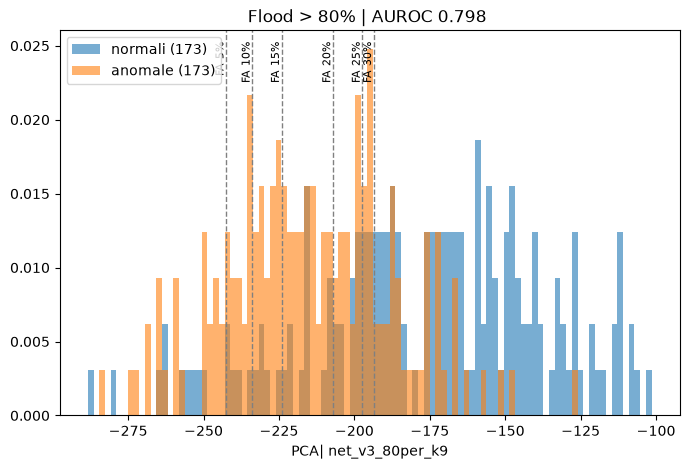

In [5]:
df = pd.read_csv(f"{RESULTS_DIR}/scores.csv")
score_normal = df[df.label == 0]['score']
score_anom = df[df.label == 1]['score']

lo, hi = np.quantile(df.score, [0.005, 0.995])                   
bins = np.linspace(lo, hi, 100)

plt.figure(figsize=(8, 5))
plt.hist(score_normal, bins=bins, alpha=0.6, density=True, label=f"normali ({len(score_normal)})")
plt.hist(score_anom, bins=bins, alpha=0.6, density=True, label=f"anomale ({len(score_anom)})")
for nome, r in results['rules'].items():                         
    if lo <= r["soglia"] <= hi:
        plt.axvline(x=r["soglia"], color='gray', linestyle='--', linewidth=1)
        plt.text(r["soglia"], plt.ylim()[1] * 0.97, nome.split("(")[-1].rstrip(")"), rotation=90, va="top", ha="right", fontsize=8)   
plt.xlabel(f"PCA | {job_name}")
plt.legend(loc="upper left")
plt.title(f"Flood > {results['min_flood_area']:.0f}% | AUROC {results['auroc']:.3f} ")
plt.show()

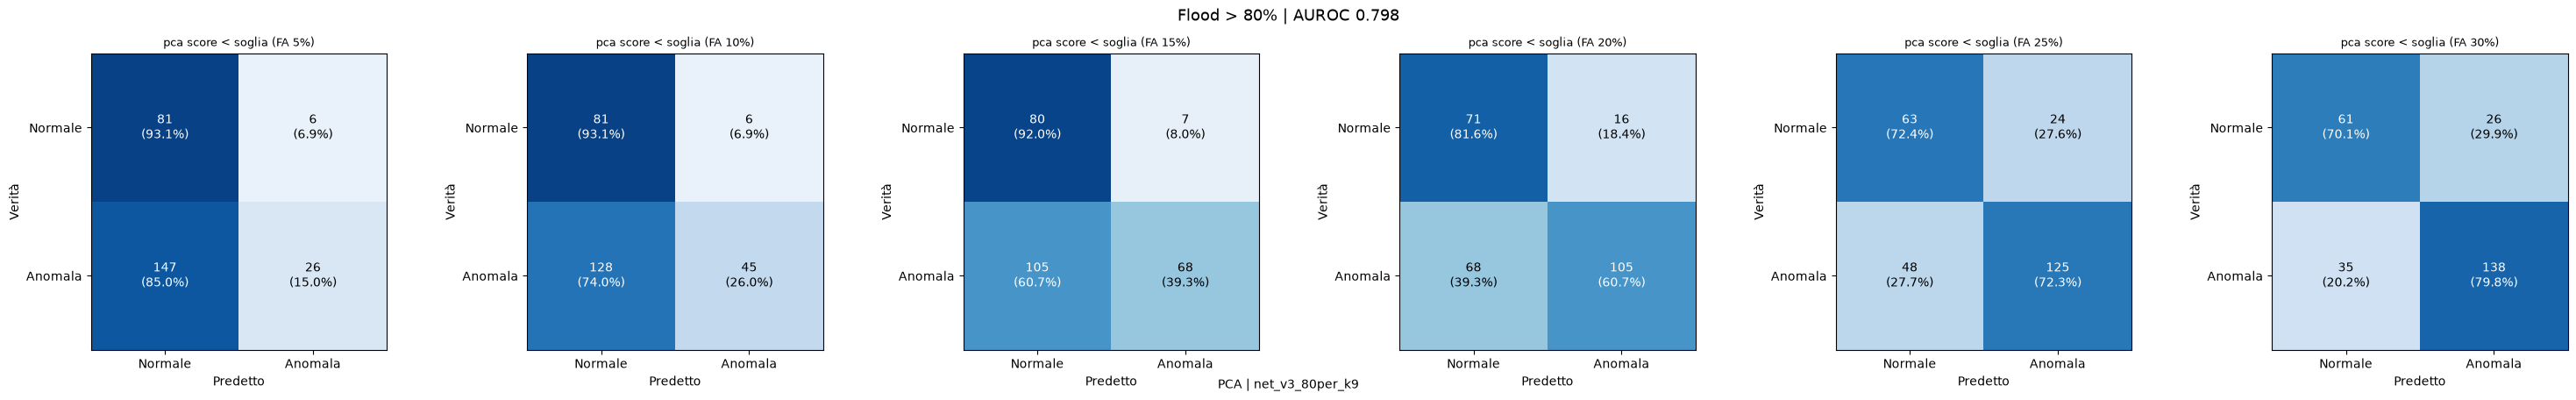

In [6]:
rules = results['rules']
fig, axes = plt.subplots(1, len(rules), figsize=(5 * len(rules), 4.5), squeeze=False)

for ax, (nome, r) in zip(axes[0], rules.items()):
    mat = np.array([[r["TN"], r["FP"]],
                     [r["FN"], r["TP"]]])
    mat_pct = mat / mat.sum(axis=1, keepdims=True) * 100

    im = ax.imshow(mat_pct, cmap="Blues", vmin=0, vmax=100)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Normale", "Anomala"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["Normale", "Anomala"])
    ax.set_xlabel("Predetto"); ax.set_ylabel("Verità")
    ax.set_title(nome, fontsize=9)

    for i in range(2):
        for j in range(2):
            color = "white" if mat_pct[i, j] > 55 else "black"
            ax.text(j, i, f"{int(mat[i, j])}\n({mat_pct[i, j]:.1f}%)",
                    ha="center", va="center", color=color, fontsize=10)

fig.suptitle(f"Flood > {results['min_flood_area']:.0f}% | AUROC {results['auroc']:.3f}", fontsize=13)
fig.text(0.5, 0.01, f"PCA | {job_name}", ha="center", va="bottom", fontsize=10)               

plt.tight_layout()
plt.show()